# DMDU workshop: Mumbai October 2026
___

### Staff

* Prof. Dr. Om Prakash Damani, Indian Institute of Technology Bombay
* Prof. Dr. Jayendran Venkateswaran, Indian Institute of Technology Bombay
* Dr. Ir. Patrick Steinmann, Delft University of Technology
* Ir. Coen van den Elshout, Delft University of Technology

### Introduction

Dear reader,

This workshop introduces Decision Making under Deep Uncertainty (DMDU) as a challenge, and Exploratory Modelling and Analysis (EMA) as a solution, to using System Dynamics for analysing and supporting policy processes in complex, dynamic, and multi-actor systems. Participants will explore how System Dynamics models can be used not primarily for prediction, but as exploratory tools to study patterns, examine plausible futures, identify vulnerabilities of candidate policies, and compare robust and adaptive strategies across uncertainty. The workshop combines a concise introduction to key DMDU concepts with hands-on exercises in which participants apply a variety of computational techniques to their own System Dynamics models to explore model behaviour and interpret the resulting patterns to derive decision-relevant insights.

To ensure smooth sailing at the start of the workshop pay attention the following points:

* This notebook contains all the instructions and material for the workshop. The notebook is in chronological order following the workshop (see the table below).
* To make you already familiar with the main concepts of DMDU before the workshop we have selected some of the foundational material of the field. We recommend reading these before the start of the workshop. These papers can be found in the workshop map.
* Download, save and extract the workshop map locally on your computer.
* Install Python and the EMA workbench (see the instructions below).

Looking forward to meet you all!

_Coen_


## Day 0

<a id="technical-preparation"></a>

### Installing the EMA workbench

Exploratory Modeling and Analysis (EMA) is a research methodology that uses computational experiments to analyze complex and uncertain systems (Bankes, 1993). That is, exploratory modeling aims at offering computational decision support for decision making under deep uncertainty and Robust Decision Making.

The EMA workbench aims at providing support for performing exploratory modeling with models developed in various modelling packages and environments. Currently, the workbench offers connectors to Vensim , Netlogo, and Excel. The EMA workbench offers support for designing experiments, performing the experiments - including support for parallel processing on both a single machine as well as on clusters-, and analysing the results.

Most of you wont have access to the Vensim DSS version, which is needed to connect your own models to EMA. The analysis and data generation will be done with predefined python models (in this notebook) and datasets (within the workshop map). However, a demonstration will be giving showing how the connector works with DSS and how to translate small SD models into python if no DSS version is available.


Lets install the workbench.
From version 2.5.0 the workbench requires Python 3.9 or higher. Make sure to update the python kernel of this notebook to Version 3.9 before installing the workbench.


In [ ]:
#Install Libraries

%pip install -q -r requirements.txt

In [ ]:
try:
    import ema_workbench
    print(f"EMA Workbench {ema_workbench.__version__} is installed and ready.")
except ImportError:
    print("EMA Workbench is not installed. Run: %pip install ema_workbench")
    %pip install -U "ema_workbench[recommended]"
    import ema_workbench
    print(f"EMA Workbench {ema_workbench.__version__} is installed and ready.")

: 

## Day 1

<a id="introduction-to-dmdu"></a>

### 1. Introduction to Decision Making Under Deep Uncertainty

<a id="open-exploration"></a>






## The model: Mexican Flu

During this model we will use a venpy model to conduct our analyses. This model is derived from an SD model built by Pruyt & Hamarat (2010) for a conference paper at the ISDC. We have chosen to use an adjusted Venpy model as most of the workshop participants do not have a Vensim DSS licence to connect vensim to EMA and venpy is native in python. The base version of the model can be found at: https://emaworkbench.readthedocs.io/en/latest/examples/example_flu.html.



The paper by Pruyt & Hamarat (2010) presents a small exploratory System Dynamics model related to the dynamics of the 2009 flu pandemic, also known as the Mexican flu, swine flu, or A(H1N1)v. The model was developed in May 2009 in order to quickly foster understanding about the possible dynamics of this new flu variant and to perform rough-cut policy explorations. Later, the model was also used to further develop and illustrate Exploratory Modelling and Analysis.
## Mexican Flu: the basic model

In the first days, weeks and months after the first reports about the outbreak of a new flu variant in Mexico and the USA, much remained unknown about the possible dynamics and consequences of the at the time plausible/imminent epidemic/pandemic of the new flu variant, first known as Swine or Mexican flu and known today as Influenza A(H1N1)v.

The exploratory model presented here is small, simple, high-level, data-poor (no complex/special structures nor detailed data beyond crude guestimates), and history-poor.

The modelled world is divided in three regions: the Western World, the densely populated Developing World, and the scarcely populated Developing World. Only the two first regions are included in the model because it is assumed that the scarcely populated regions are causally less important for dynamics of flu pandemics. Below, the figure shows the basic stock-and-flow structure; its a classic S.I.E.R structure tracking (diseased) population. For a more elaborate description of the model, see Pruyt & Hamarat (2010).

![Flu model diagram](https://raw.githubusercontent.com/IITB-TUD-DMDU/IITB-TUD-DMDU-Workshop/main/IITB-TUD-DMDU-Workshop-Folder/flu-diagram-enhanced.png)

Import all libraries

In [29]:
from pathlib import Path
import importlib.util
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from ema_workbench.analysis import lines
from scipy.stats import gaussian_kde
from IPython.display import display
from ema_workbench import Model, RealParameter, TimeSeriesOutcome, SequentialEvaluator, perform_experiments
from ema_workbench.analysis.plotting import kde_over_time
from ema_workbench.analysis import Density
from SALib.sample import sobol as sobol_sample
from SALib.analyze import sobol, pawn
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import classification_report, balanced_accuracy_score, silhouette_score

Set seed and number of runs

### Choose the outcome and scalar metric
Default: **infected population in region 1**, using its **peak** for sensitivity and threshold discovery.
All ten stocks in both regions are available through OUTCOME_NAMES. Change OUTCOME, then rerun this settings cell and all subsequent cells. All plots, Sobol, PAWN, convergence, threshold discovery, early-peak discovery and clustering use that setting.
METRIC selects peak, final, or time integral for sensitivity and threshold discovery. Final-state KDE always uses the final time. Clustering uses full trajectories; early-peak discovery uses the stock maximum.
For cumulative deceased or recovered stocks, final is usually useful. Monotonic susceptible/immune trajectories may peak initially; choose final or integral if peak is uninformative. Adjust OUTCOME_THRESHOLD to match the selected metric and units.
The ensemble stores all ten stocks. The structured Sobol design is rerun for the chosen scalar metric; its outputs cannot be substituted from the exploratory sample.


In [3]:
SEED = 42
NR_EXPERIMENTS = 1000
SOBOL_N = 256  # power of two; actual simulations = N * (17 + 2)

# Change these settings, then rerun this cell and all analysis cells below it.
OUTCOME = "infected_population_region_1"
METRIC = "peak"  # "peak", "final", or "integral"
OUTCOME_NAMES = [f"{stock}_population_region_{region}"
                 for stock in ["susceptible", "infected", "recovered", "immune", "deceased"]
                 for region in [1, 2]]
assert OUTCOME in OUTCOME_NAMES
assert METRIC in {"peak", "final", "integral"}
OUTCOME_LABEL = OUTCOME.replace("_", " ").capitalize()
METRIC_LABEL = f"{METRIC.capitalize()} of {OUTCOME_LABEL.lower()}"
DISPLAY_SCALE = 1e6
AXIS_LABEL = f"{OUTCOME_LABEL} (millions of people)"
# Teaching thresholds, not policy recommendations. Adjust to the chosen outcome/metric.
OUTCOME_THRESHOLD = 1_000_000
EARLY_TIME = 15
MIN_PEAK_POPULATION = 10_000

def summarize_trajectory(values, times):
    values = np.asarray(values, dtype=float)
    if METRIC == "peak":
        return np.max(values, axis=-1)
    if METRIC == "final":
        return values[..., -1]
    # Trapezoidal integral, compatible with NumPy versions before and after 2.0.
    return np.sum((values[..., 1:] + values[..., :-1]) * .5 * np.diff(times), axis=-1)

Check path

In [4]:
MODEL_PATH = Path.cwd() / 'models' / 'Flu model.py'
assert MODEL_PATH.is_file(), f'Cannot find {MODEL_PATH}; change MODEL_PATH if needed.'
spec = importlib.util.spec_from_file_location('flu_module', MODEL_PATH)
flu_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = flu_module
spec.loader.exec_module(flu_module)
flu_model = flu_module.flu_model

In [5]:
# (code, descriptive name, lower bound, upper bound)
PARAMETERS = [
    ('x11', 'Seasonal immunity R1', 0, .5),
    ('x12', 'Seasonal immunity R2', 0, .5),
    ('x21', 'Fatality rate R1', .0001, .1),
    ('x22', 'Fatality rate R2', .0001, .1),
    ('x31', 'Initial immune fraction R1', 0, .5),
    ('x32', 'Initial immune fraction R2', 0, .5),
    ('x41', 'Interregional contact rate', 0, .9),
    ('x51', 'Permanent immunity R1', 0, .5),
    ('x52', 'Permanent immunity R2', 0, .5),
    ('x61', 'Recovery time R1', .1, .8),
    ('x62', 'Recovery time R2', .1, .8),
    ('x81', 'Root contact rate R1', 1, 10),
    ('x82', 'Root contact rate R2', 1, 10),
    ('x91', 'Infection rate R1', 0, .1),
    ('x92', 'Infection rate R2', 0, .1),
    ('x101', 'Normal contact rate R1', 0, 200),
    ('x102', 'Normal contact rate R2', 0, 200),
]
names = [p[0] for p in PARAMETERS]
labels = {p[0]: f'{p[0]}: {p[1]}' for p in PARAMETERS}
problem = {'num_vars': len(names), 'names': names,
           'bounds': [[p[2], p[3]] for p in PARAMETERS]}
model = Model('mexicanFlu', function=flu_model)
model.uncertainties = [RealParameter(p[0], p[2], p[3]) for p in PARAMETERS]

Set model outcomes

In [6]:
# Record all ten stocks so plots can switch outcomes without rerunning the ensemble.
model.outcomes = [TimeSeriesOutcome("TIME")] + [TimeSeriesOutcome(n) for n in OUTCOME_NAMES]
# Check one valid parameter combination before launching the ensemble.
probe = flu_model(**{p[0]: (p[2] + p[3]) / 2 for p in PARAMETERS})
missing = set(OUTCOME_NAMES) - set(probe)
assert not missing, f"Model is missing stock histories: {missing}. Use the supplied all-stocks model."

## Inspecting the model

In [7]:
table = pd.DataFrame(
    PARAMETERS,
    columns=["Code", "Parameter", "Minimum", "Maximum"],
)
print(table.to_string(index=False, col_space=2))

Code                  Parameter  Minimum  Maximum
 x11       Seasonal immunity R1   0.0000      0.5
 x12       Seasonal immunity R2   0.0000      0.5
 x21           Fatality rate R1   0.0001      0.1
 x22           Fatality rate R2   0.0001      0.1
 x31 Initial immune fraction R1   0.0000      0.5
 x32 Initial immune fraction R2   0.0000      0.5
 x41 Interregional contact rate   0.0000      0.9
 x51      Permanent immunity R1   0.0000      0.5
 x52      Permanent immunity R2   0.0000      0.5
 x61           Recovery time R1   0.1000      0.8
 x62           Recovery time R2   0.1000      0.8
 x81       Root contact rate R1   1.0000     10.0
 x82       Root contact rate R2   1.0000     10.0
 x91          Infection rate R1   0.0000      0.1
 x92          Infection rate R2   0.0000      0.1
x101     Normal contact rate R1   0.0000    200.0
x102     Normal contact rate R2   0.0000    200.0


**Student task:** Predict three influential inputs before running the model. Explain the mechanisms and why the assumed ranges matter.

## Open exploration: run the ensemble
This uses a separate exploratory sample. Do not use this sample for Sobol indices.

In [8]:
SEED = 42
np.random.seed(SEED)
with SequentialEvaluator(model) as evaluator:
    experiments, outcomes = perform_experiments(model, scenarios=NR_EXPERIMENTS, evaluator=evaluator)

100%|██████████████████████████████████████| 1000/1000 [01:08<00:00, 14.59it/s]


In [9]:
# Shared data for EVERY analysis below. Rerun after changing OUTCOME or METRIC.
time = np.asarray(outcomes["TIME"][0], dtype=float)
trajectories = np.asarray(outcomes[OUTCOME], dtype=float)
assert np.isfinite(trajectories).all(), "Investigate non-finite model output."
assert np.allclose(outcomes["TIME"], time), "Runs must share a time grid."
assert np.all(np.diff(time) > 0)
X = experiments.loc[:, names].astype(float).reset_index(drop=True)
metric_values = summarize_trajectory(trajectories, time)
assert np.std(metric_values) > 0, "The selected metric is constant: choose another metric."
peak_time = time[np.argmax(trajectories, axis=1)]
peak_population = trajectories.max(axis=1)

def safe_kde(values, grid):
    values = np.asarray(values, dtype=float)
    if np.ptp(values) <= 1e-12 * max(1., abs(values.mean())):
        return None
    return gaussian_kde(values)(grid)

print("Selected:", OUTCOME_LABEL, "| Sensitivity/scenario metric:", METRIC)
print("Integral units are people × model-time units; peak/final units are people.")
display(pd.Series(metric_values, name=METRIC_LABEL).describe())


Selected: Infected population region 1 | Sensitivity/scenario metric: peak
Integral units are people × model-time units; peak/final units are people.


count    1.000000e+03
mean     8.658784e+06
std      2.173755e+07
min      1.000000e+01
25%      1.000000e+01
50%      5.418900e+03
75%      1.706642e+06
max      1.457085e+08
Name: Peak of infected population region 1, dtype: float64

### 1. Time series

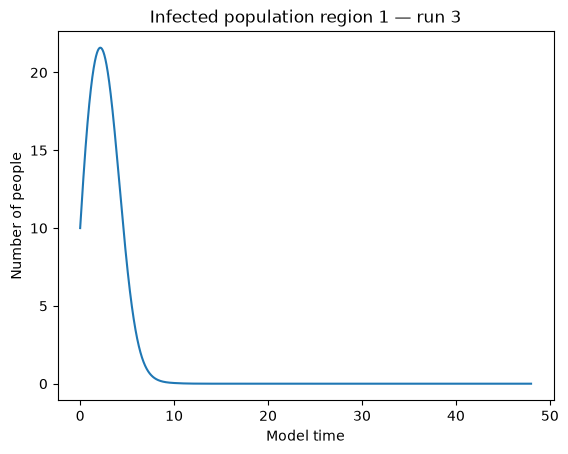

In [22]:
RUN = 2
fig, axes = lines(experiments, outcomes, outcomes_to_show=OUTCOME,
                  experiments_to_show=[RUN], titles={OUTCOME: f"{OUTCOME_LABEL} — run {RUN + 1}"})
axes[OUTCOME].set(xlabel="Model time", ylabel="Number of people")
plt.show()

**Student task:** Change the run number a couple of times. Identify two distinct trajectory patterns. What mechanisms could explain their timing and magnitude?

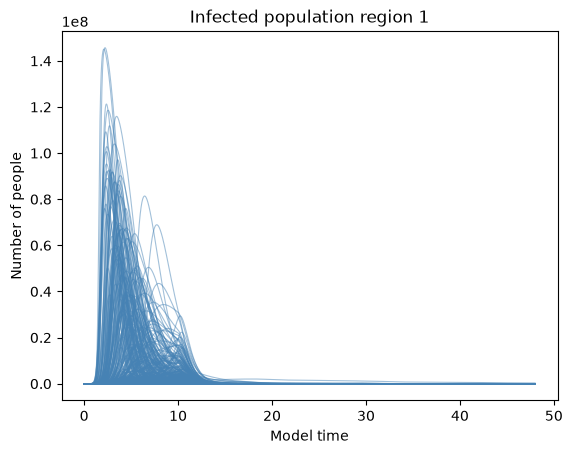

In [35]:
fig, axes = lines(
    experiments,
    outcomes,
    outcomes_to_show=OUTCOME,
    titles={OUTCOME: OUTCOME_LABEL},
)

ax = axes[OUTCOME]

for line in ax.lines:
    line.set_color("steelblue")
    line.set_alpha(0.3)
    line.set_linewidth(0.8)

ax.set(xlabel="Model time", ylabel="Number of people")
plt.show()

### 2. Kernel density of end states
A KDE smooths the empirical distribution. It can extend outside physical bounds; the plot shows only nonnegative population values.

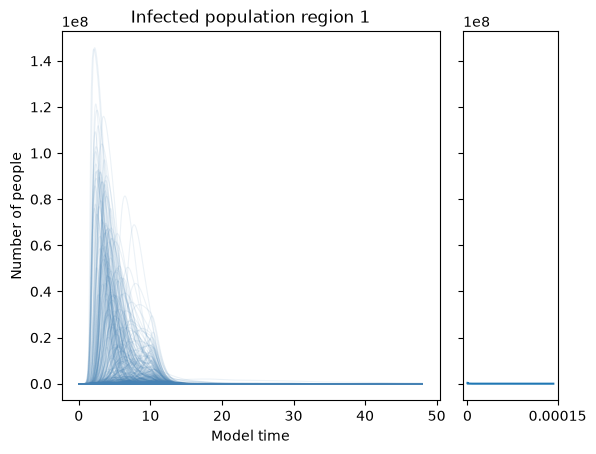

In [34]:
from ema_workbench.analysis import Density

fig, axes = lines(
    experiments,
    outcomes,
    outcomes_to_show=OUTCOME,
    titles={OUTCOME: OUTCOME_LABEL},
    density=Density.KDE,
)

ax = axes[OUTCOME]

for line in ax.lines:
    line.set_color("steelblue")
    line.set_alpha(0.3)
    line.set_linewidth(0.8)

ax.set(xlabel="Model time", ylabel="Number of people")
plt.show()

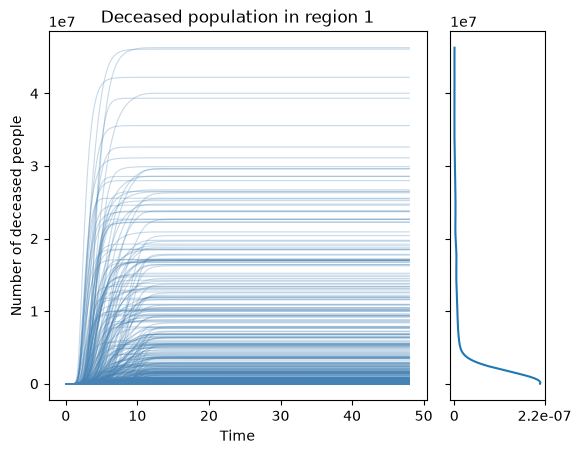

In [37]:
fig, axes = lines(
    experiments,
    outcomes,
    outcomes_to_show="deceased_population_region_1",
    titles={"deceased_population_region_1": "Deceased population in region 1"},
    density=Density.KDE,
)

ax = axes["deceased_population_region_1"]
for line in ax.lines:
    line.set_color("steelblue")
    line.set_alpha(0.3)
    line.set_linewidth(0.8)
ax.set_xlabel("Time")
ax.set_ylabel("Number of deceased people")

plt.show()

**Student task:** What are you seeing from the KDE, what is the difference between the two KDE? discuss

### 3. Kernel density at every time step
Each column is a KDE over runs at one model time. All 6,145 time points are evaluated. Identical columns, including the initial condition, are masked because their distribution is a point mass. Density is shown on a log scale so early concentration does not dominate.

C:\Users\csvandenelshou\PycharmProjects\DMDU_mumbai\.venv\Lib\site-packages\ema_workbench\analysis\plotting_util.py:354: RuntimeWarning: invalid value encountered in divide
  kde_x = kde_x / np.max(kde_x)


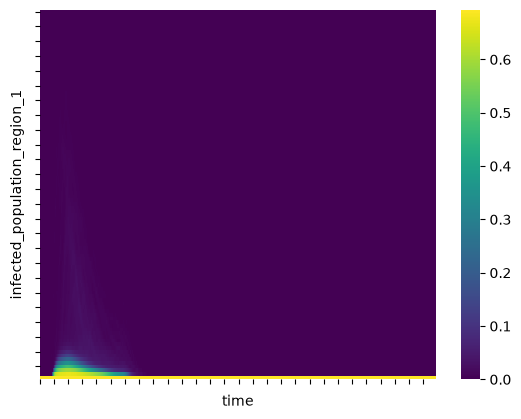

In [28]:
fig, axes = kde_over_time(
    experiments,
    outcomes,
    outcomes_to_show="infected_population_region_1",
    log=True,
)
plt.show()

**Student task:** What are we seeing? Discuss

### 4. Time series colored by one input

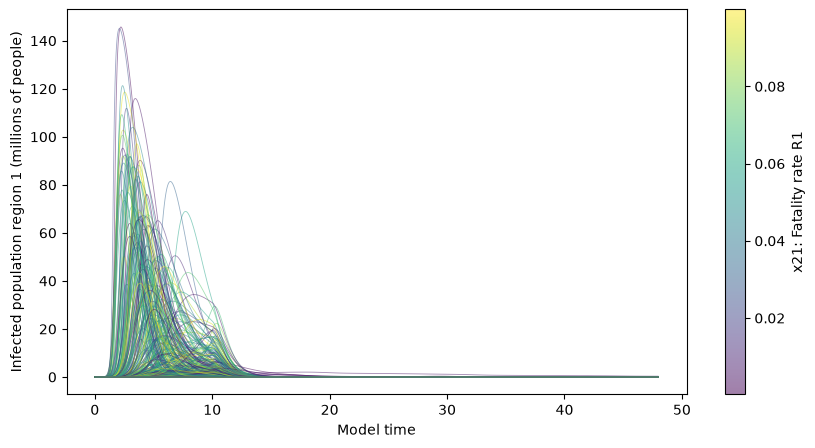

In [15]:
COLOR_PARAMETER = 'x21'  # change to any input code
segments = np.stack([np.column_stack([time, run / 1e6]) for run in trajectories])
fig, ax = plt.subplots(figsize=(10, 5))
collection = LineCollection(segments, cmap='viridis', linewidths=.6, alpha=.5)
collection.set_array(X[COLOR_PARAMETER].to_numpy())
ax.add_collection(collection); ax.autoscale()
fig.colorbar(collection, ax=ax, label=labels[COLOR_PARAMETER])
ax.set(xlabel='Model time', ylabel=AXIS_LABEL)
plt.show()

**Student task:** Compare coloring by x21 and x101. Is the relationship monotonic? Why does a color pattern alone not establish an isolated causal effect?

## Global sensitivity analysis
### 5. Sobol indices for selected scalar metric
Sobol needs its own structured design. Independent uniform inputs are assumed. S1 measures a first-order variance contribution; ST includes interactions. Second-order indices are not computed. Never shuffle or remove design rows.

Model evaluations: 4,864


100%|██████████████████████████████████████| 4864/4864 [08:45<00:00,  9.26it/s]


,S1,ST,S1_conf,ST_conf
x101,4.420469e-02,5.097938e-01,0.064219,2.137319e-01
x91,2.138991e-01,4.314006e-01,0.177053,1.400122e-01
x81,7.619904e-02,2.517481e-01,0.128969,9.037090e-02
x61,6.670023e-02,2.395213e-01,0.051754,1.438613e-01
x51,2.734360e-02,1.700996e-01,0.044073,7.201301e-02
x11,-1.646544e-02,3.539072e-02,0.021965,2.679793e-02
x31,-4.507569e-03,1.220200e-03,0.006817,7.191792e-04
x82,9.024107e-04,9.458621e-04,0.004101,1.720014e-03
x102,1.769024e-03,7.571784e-04,0.006072,8.771715e-04
x92,2.473113e-03,5.678805e-04,0.003732,8.525050e-04


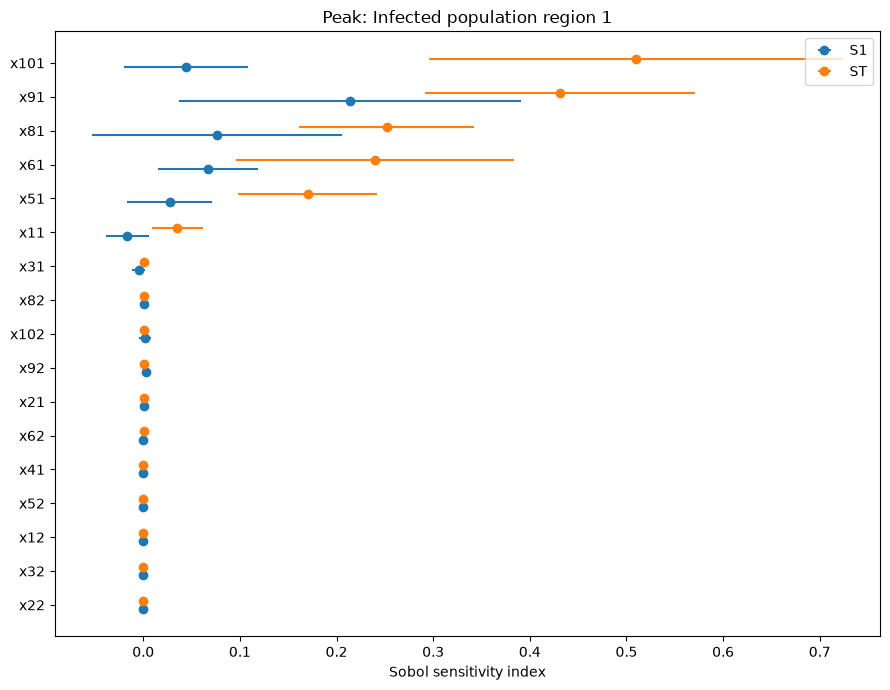

In [16]:


from IPython.display import display
from ema_workbench import (
    Model,
    ScalarOutcome,
    SequentialEvaluator,
    perform_experiments,
)
from ema_workbench.em_framework import get_SALib_problem
from ema_workbench.em_framework.evaluators import Samplers
from SALib.analyze import sobol, pawn

# Use the same selected outcome and metric throughout steps 5–10.
ANALYSIS_OUTCOME = OUTCOME
ANALYSIS_METRIC = METRIC
OUTCOME_LABEL = ANALYSIS_OUTCOME.replace("_", " ").capitalize()
METRIC_LABEL = f"{ANALYSIS_METRIC.capitalize()}: {OUTCOME_LABEL}"

def summarize(values, times):
    values = np.asarray(values, dtype=float)
    times = np.asarray(times, dtype=float)

    if ANALYSIS_METRIC == "peak":
        return np.max(values, axis=-1)
    if ANALYSIS_METRIC == "final":
        return values[..., -1]
    if ANALYSIS_METRIC == "integral":
        return np.sum(
            0.5 * (values[..., 1:] + values[..., :-1])
            * np.diff(times),
            axis=-1,
        )
    raise ValueError("METRIC must be 'peak', 'final', or 'integral'.")

# Prepare the existing exploratory ensemble.
time = np.asarray(outcomes["TIME"][0], dtype=float)
trajectories = np.asarray(outcomes[ANALYSIS_OUTCOME], dtype=float)

assert np.isfinite(trajectories).all()
assert np.allclose(outcomes["TIME"], time)
assert np.all(np.diff(time) > 0)

problem = get_SALib_problem(model.uncertainties)
names = problem["names"]
X = experiments.loc[:, names].astype(float).reset_index(drop=True)
metric_values = summarize(trajectories, time)

# Return only the selected scalar, avoiding storage of Sobol trajectories.
def sensitivity_function(**parameters):
    result = flu_model(**parameters)
    value = summarize(result[ANALYSIS_OUTCOME], result["TIME"])
    return {"selected_metric": float(value)}

sensitivity_model = Model("fluSensitivity", function=sensitivity_function)
sensitivity_model.uncertainties = list(model.uncertainties)
sensitivity_model.constants = list(model.constants)
sensitivity_model.outcomes = [ScalarOutcome("selected_metric")]

SOBOL_N = 256  # Power of two; increase for stronger convergence checks.
assert SOBOL_N >= 2 and SOBOL_N & (SOBOL_N - 1) == 0

print(f"Model evaluations: {SOBOL_N * (len(names) + 2):,}")

np.random.seed(SEED)

with SequentialEvaluator(sensitivity_model) as evaluator:
    sobol_experiments, sobol_outcomes = perform_experiments(
        sensitivity_model,
        scenarios=SOBOL_N,
        evaluator=evaluator,
        uncertainty_sampling=Samplers.SOBOL,
        uncertainty_sampling_kwargs={"calc_second_order": False},
    )

sobol_Y = np.asarray(sobol_outcomes["selected_metric"], dtype=float)

assert np.isfinite(sobol_Y).all(), "Investigate invalid runs; do not remove rows."
assert np.std(sobol_Y) > 0, "Selected metric is constant."

Si = sobol.analyze(
    problem,
    sobol_Y,
    calc_second_order=False,
    seed=SEED,
)

sobol_table = pd.DataFrame(
    {key: Si[key] for key in ["S1", "ST", "S1_conf", "ST_conf"]},
    index=names,
)

display(sobol_table.sort_values("ST", ascending=False))

order = np.argsort(Si["ST"])
positions = np.arange(len(names))

fig, ax = plt.subplots(figsize=(9, 7))
ax.errorbar(
    Si["S1"][order], positions - 0.12,
    xerr=Si["S1_conf"][order], fmt="o", label="S1",
)
ax.errorbar(
    Si["ST"][order], positions + 0.12,
    xerr=Si["ST_conf"][order], fmt="o", label="ST",
)
ax.set_yticks(positions, [names[i] for i in order])
ax.set(title=METRIC_LABEL, xlabel="Sobol sensitivity index")
ax.legend()
plt.tight_layout()
plt.show()

**Student task:** Compare S1 and ST for the top three inputs. What do their gaps suggest? Explain why negative estimates or ST above one should trigger convergence checks rather than be interpreted literally.

### 6. PAWN sensitivity
PAWN uses distribution changes rather than variance decomposition. This uses the exploratory ensemble, conditioning each input on ten intervals.

,minimum,median,maximum,CV
x101,0.076000,0.202500,0.276000,0.295573
x91,0.052000,0.194000,0.369000,0.445285
x102,0.071000,0.172500,0.269677,0.360380
x92,0.092000,0.170000,0.234576,0.327299
x61,0.048000,0.147379,0.295000,0.477595
x62,0.092000,0.130500,0.211000,0.259862
x81,0.042000,0.111136,0.144000,0.293534
x51,0.059000,0.105000,0.177778,0.327759
x32,0.040000,0.090980,0.144000,0.360695
x21,0.054000,0.090000,0.125000,0.220805


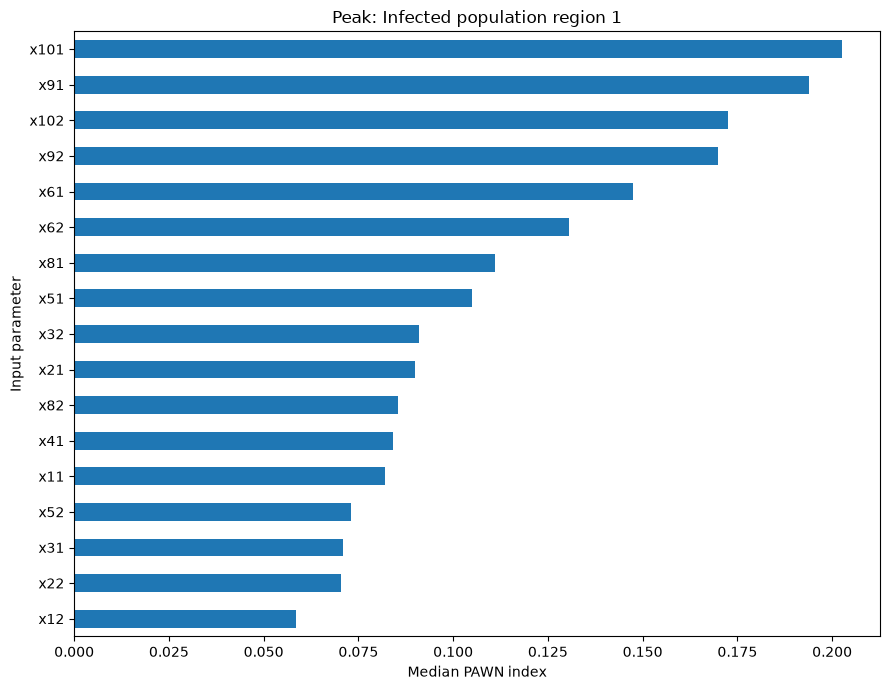

In [17]:
assert np.std(metric_values) > 0, "Selected metric is constant."

PAWN_INTERVALS = 10

pawn_result = pawn.analyze(
    problem,
    X.to_numpy(),
    metric_values,
    S=PAWN_INTERVALS,
    seed=SEED,
)

pawn_table = pd.DataFrame(
    {
        key: pawn_result[key]
        for key in ["minimum", "median", "maximum", "CV"]
    },
    index=names,
)

display(pawn_table.sort_values("median", ascending=False))

fig, ax = plt.subplots(figsize=(9, 7))
pawn_table["median"].sort_values().plot.barh(ax=ax)
ax.set(
    title=METRIC_LABEL,
    xlabel="Median PAWN index",
    ylabel="Input parameter",
)
plt.tight_layout()
plt.show()

**Student task:** Compare PAWN and Sobol rankings. Explain why they may disagree. Repeat PAWN with S=5 and S=20 and discuss the number of observations per conditioning interval.

### 7. Convergence
Use complete nested Sobol blocks from the same scrambled design; do not take arbitrary random subsets. The shaded intervals are bootstrap uncertainty estimates, not a guarantee of convergence. PAWN uses increasing exploratory subsets and is an indicative stability check, not an independent replicate study.

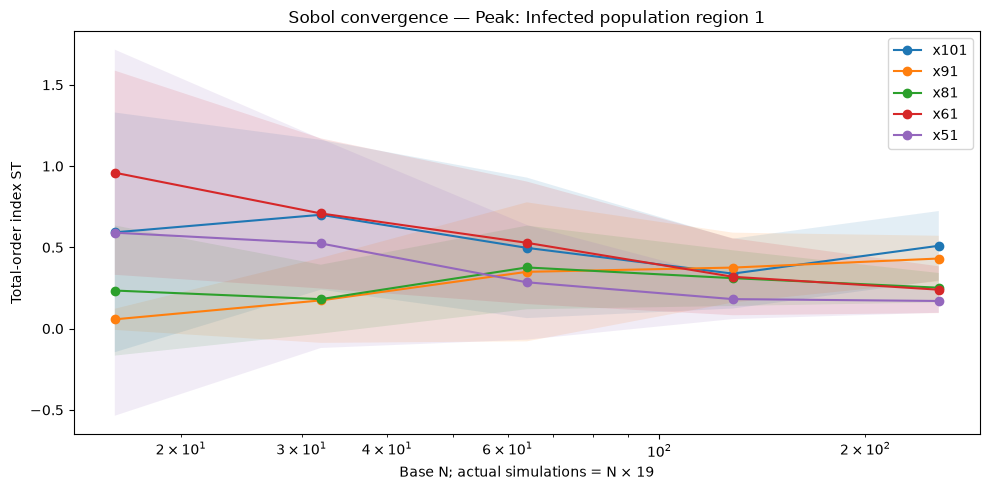

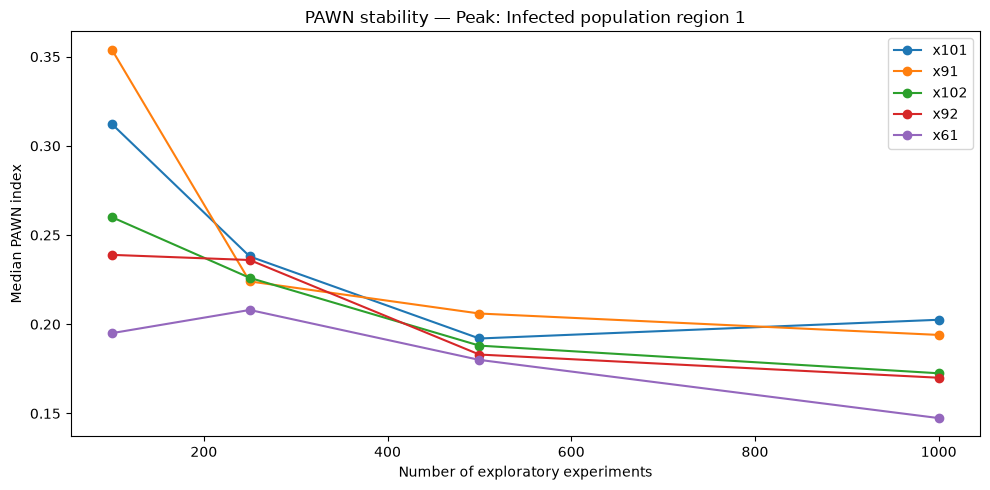

In [18]:
block_size = len(names) + 2

base_sizes = [
    2**power
    for power in range(4, int(np.log2(SOBOL_N)) + 1)
]
if SOBOL_N not in base_sizes:
    base_sizes.append(SOBOL_N)

convergence_rows = []

for n in base_sizes:
    estimate = sobol.analyze(
        problem,
        sobol_Y[:n * block_size],
        calc_second_order=False,
        seed=SEED,
    )

    for i, name in enumerate(names):
        convergence_rows.append({
            "N": n,
            "parameter": name,
            "ST": estimate["ST"][i],
            "CI": estimate["ST_conf"][i],
        })

convergence = pd.DataFrame(convergence_rows)

fig, ax = plt.subplots(figsize=(10, 5))

for name in sobol_table.nlargest(5, "ST").index:
    selected = convergence[convergence["parameter"] == name]
    n = selected["N"].to_numpy()
    st = selected["ST"].to_numpy()
    ci = selected["CI"].to_numpy()

    ax.plot(n, st, "o-", label=name)
    ax.fill_between(n, st - ci, st + ci, alpha=0.12)

ax.set(
    title=f"Sobol convergence — {METRIC_LABEL}",
    xlabel=f"Base N; actual simulations = N × {block_size}",
    ylabel="Total-order index ST",
    xscale="log",
)
ax.legend()
plt.tight_layout()
plt.show()

# PAWN stability using increasing exploratory sample sizes.
sample_sizes = sorted({
    min(n, len(X))
    for n in [100, 250, 500, 1000, len(X)]
})

pawn_estimates = [
    pawn.analyze(
        problem,
        X.iloc[:n].to_numpy(),
        metric_values[:n],
        S=PAWN_INTERVALS,
        seed=SEED,
    )
    for n in sample_sizes
]

fig, ax = plt.subplots(figsize=(10, 5))

for name in pawn_table.nlargest(5, "median").index:
    i = names.index(name)
    ax.plot(
        sample_sizes,
        [estimate["median"][i] for estimate in pawn_estimates],
        "o-",
        label=name,
    )

ax.set(
    title=f"PAWN stability — {METRIC_LABEL}",
    xlabel="Number of exploratory experiments",
    ylabel="Median PAWN index",
)
ax.legend()
plt.tight_layout()
plt.show()

**Student task:** Define a convergence criterion before increasing N: for example, stable top-three rankings and sufficiently narrow confidence intervals. Are those conditions met? Repeat with another seed before making a strong claim.

## Scenario discovery
A shallow classification tree induces readable input rules. Held-out scores assess prediction of the chosen event; they do not establish causality. Split the inputs before fitting rules. Adjust an event definition only with a stated rationale, not to improve its test score.

Peak: Infected population region 1 > 1,000,000
Cases of interest: 272 / 1000
Prevalence: 27.2%


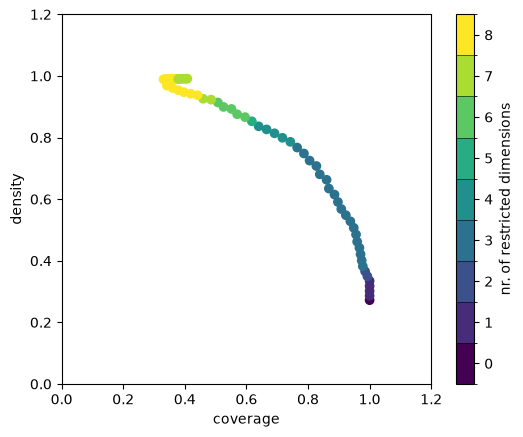

coverage      0.408088
density       0.991071
id           63.000000
k           111.000000
mass          0.112000
mean          0.991071
n           112.000000
res_dim       7.000000
Name: 63, dtype: float64

          box 63                                    
             min         max      qp value  qp value
x22     0.000200    0.089554           NaN  0.056801
x32     0.029753    0.402052  4.994183e-02  0.019768
x51     0.000307    0.430500           NaN  0.003196
x61     0.338089    0.799817  4.120105e-11       NaN
x62     0.129327    0.799733  2.111829e-01       NaN
x91     0.039880    0.099941  1.525503e-17       NaN
x101  103.585827  199.827113  2.040285e-20       NaN



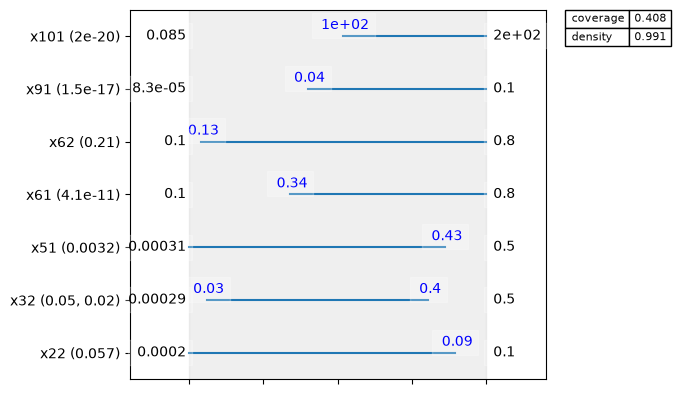

In [19]:
from ema_workbench.analysis import prim

OUTCOME_THRESHOLD = 1_000_000  # Adjust for the selected outcome and metric.

def run_prim(target, title):
    target = np.asarray(target, dtype=bool)

    print(title)
    print(f"Cases of interest: {target.sum()} / {len(target)}")
    print(f"Prevalence: {target.mean():.1%}")

    if target.all() or not target.any():
        print("PRIM needs both cases of interest and other cases.")
        return None, None

    search = prim.Prim(
        X,
        target,
        peel_alpha=0.05,
        paste_alpha=0.05,
        mass_min=0.05,
    )

    box = search.find_box()

    if box is None:
        print("No box found.")
        return search, None

    box.show_tradeoff()
    plt.show()

    # Display the currently selected box and its input restrictions.
    box.inspect()
    box.inspect(style="graph")
    plt.show()

    return search, box

above_threshold = metric_values > OUTCOME_THRESHOLD

threshold_prim, threshold_box = run_prim(
    above_threshold,
    f"{METRIC_LABEL} > {OUTCOME_THRESHOLD:,}",
)



### 8. Threshold criterion
The example threshold is a teaching choice, not a policy recommendation.

In [20]:
# Choose an available index shown in the trade-off plot.
threshold_box.inspect(5)
threshold_box.select(5)

coverage      0.992647
density       0.349741
id            5.000000
k           270.000000
mass          0.772000
mean          0.349741
n           772.000000
res_dim       2.000000
Name: 5, dtype: float64

        box 5                             
          min       max  qp value qp value
x61  0.136600  0.799817  0.195796      NaN
x91  0.018685  0.099941  0.000051      NaN



**Student task:** Justify a outcome threshold. Explain one rule in model terms. Interpret precision as rule reliability and recall as event coverage. How do prevalence and the threshold affect the findings?

### 10. Clustering trajectories + rule induction
Split runs first. Fit K-means on training outcome trajectories, then assign test trajectories to fixed training centroids. A tree learns input rules for these labels. Curves are sampled at 100 common time points and divided by one shared scale; magnitude and timing both matter. Per-run normalization would ask a different question.

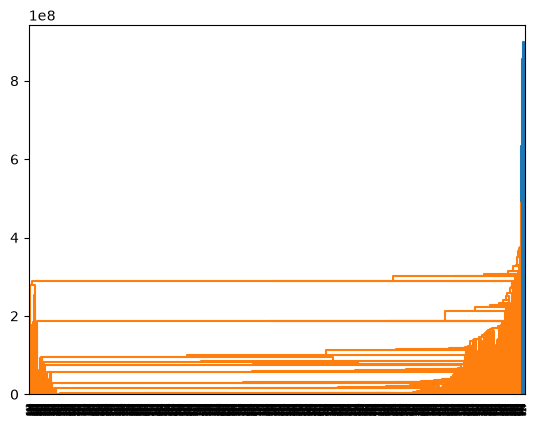

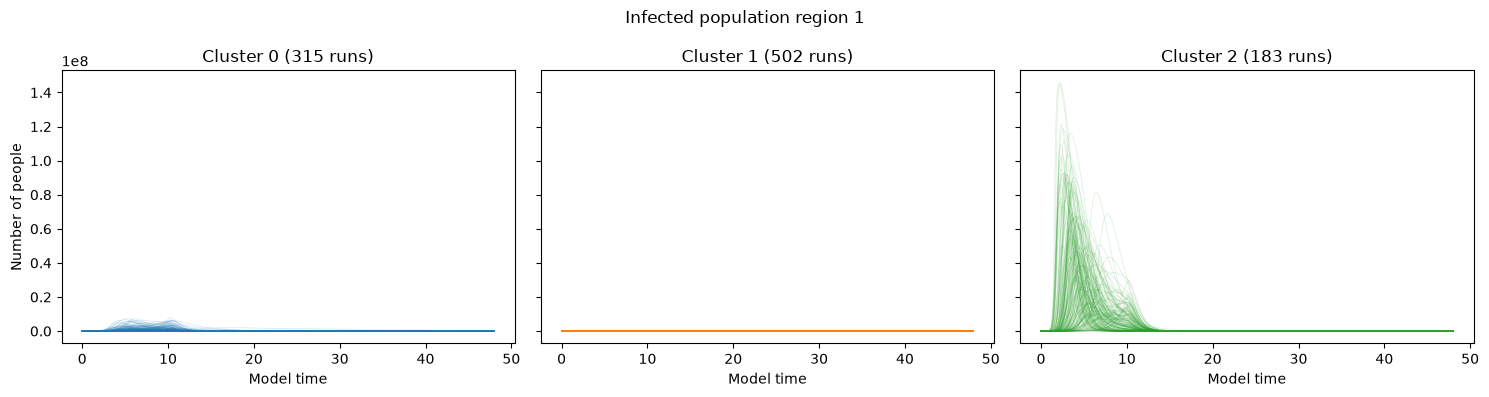

In [39]:
from ema_workbench.analysis import clusterer, cart, lines
from ema_workbench.analysis.scenario_discovery_util import RuleInductionType

N_CLUSTERS = 3

# Full trajectories for the selected outcome.
data = np.asarray(outcomes[ANALYSIS_OUTCOME], dtype=float)

assert np.isfinite(data).all()
assert 2 <= N_CLUSTERS < len(data)

# CID requires nonzero trajectory complexity.
complexity = np.sqrt(np.sum(np.diff(data, axis=1) ** 2, axis=1))
if np.any(complexity == 0):
    raise ValueError(
        "Some trajectories are constant, making standard CID undefined. "
        "Choose another outcome or explicitly handle constant trajectories "
        "before clustering."
    )

distances = clusterer.calculate_cid(data)

assert np.isfinite(distances).all(), "CID produced invalid distances."

clusterer.plot_dendrogram(distances)
plt.show()

clusters = clusterer.apply_agglomerative_clustering(
    distances,
    n_clusters=N_CLUSTERS,
)

cluster_experiments = experiments.copy()
cluster_experiments["clusters"] = clusters.astype(object)

fig, axes = plt.subplots(
    1, N_CLUSTERS,
    figsize=(5 * N_CLUSTERS, 4),
    sharex=True,
    sharey=True,
    squeeze=False,
)

for c, ax in enumerate(axes[0]):
    selected = data[clusters == c]

    ax.plot(
        time,
        selected.T,
        color=plt.get_cmap("tab10")(c),
        alpha=0.15,
        linewidth=0.6,
    )

    ax.set(
        title=f"Cluster {c} ({len(selected)} runs)",
        xlabel="Model time",
    )

axes[0, 0].set_ylabel("Number of people")
fig.suptitle(OUTCOME_LABEL)
plt.tight_layout()
plt.show()

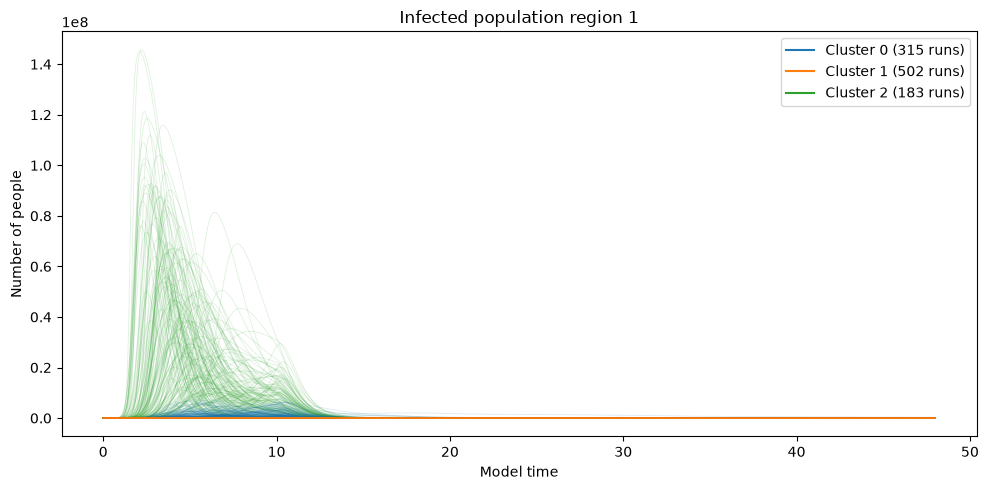

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))

# Green at the back, then blue, then orange on top
for zorder, c in enumerate([2, 0, 1], start=1):
    selected = data[clusters == c]

    ax.plot(
        time,
        selected.T,
        color=plt.get_cmap("tab10")(c),
        alpha=0.15,
        linewidth=0.6,
        zorder=zorder,
    )

# Clear legend with opaque colors
from matplotlib.lines import Line2D

handles = [
    Line2D(
        [0], [0],
        color=plt.get_cmap("tab10")(c),
        label=f"Cluster {c} ({np.sum(clusters == c)} runs)",
    )
    for c in range(N_CLUSTERS)
]

ax.legend(handles=handles)
ax.set(
    title=OUTCOME_LABEL,
    xlabel="Model time",
    ylabel="Number of people",
)

plt.tight_layout()
plt.show()

In [43]:
display(
    pd.Series(clusters, name="Cluster")
    .value_counts()
    .sort_index()
    .rename("Number of runs")
)

# Explain cluster membership through input-space rules.
cluster_cart = cart.CART(
    X,
    clusters,
    mass_min=0.05,
    mode=RuleInductionType.CLASSIFICATION,
)

cluster_cart.build_tree()

Cluster
0    315
1    502
2    183
Name: Number of runs, dtype: int64

In [41]:

for number, (box, statistics) in enumerate(
    zip(cluster_cart.boxes, cluster_cart.stats),
    start=1,
):
    print(f"\nRule {number}")
    display(box)
    print(statistics)


Rule 1


,x11,x12,x21,x22,x31,x32,x41,x51,x52,x61,x62,x81,x82,x91,x92,x101,x102
0,0.000450,0.000156,0.00020,0.000200,0.000413,0.000294,0.000886,0.000307,0.000306,0.100448,0.100327,1.008077,1.002462,0.000083,0.000057,0.085155,0.104017
1,0.499547,0.499704,0.09992,0.099962,0.499855,0.499664,0.899684,0.199756,0.499774,0.799817,0.799733,9.998351,9.999290,0.035692,0.078368,199.827113,98.729744


{'gini': 0.21839999999999993, 'mass': 0.05, 'box_composition': [3, 44, 3], 'res dim': 4}

Rule 2


,x11,x12,x21,x22,x31,x32,x41,x51,x52,x61,x62,x81,x82,x91,x92,x101,x102
0,0.000450,0.000156,0.00020,0.000200,0.000413,0.000294,0.000886,0.199756,0.000306,0.100448,0.100327,1.008077,1.002462,0.000083,0.000057,0.085155,0.104017
1,0.499547,0.499704,0.09992,0.099962,0.499855,0.499664,0.899684,0.499993,0.499774,0.799817,0.799733,9.998351,9.999290,0.035692,0.078368,199.827113,98.729744


{'gini': 0.0, 'mass': 0.084, 'box_composition': [0, 84, 0], 'res dim': 4}

Rule 3


...

{'gini': 0.4430473372781064, 'mass': 0.052, 'box_composition': [37, 11, 4], 'res dim': 4}

Rule 15


,x11,x12,x21,x22,x31,x32,x41,x51,x52,x61,x62,x81,x82,x91,x92,x101,x102
0,0.000450,0.000156,0.00020,0.000200,0.000413,0.000294,0.000886,0.000307,0.000306,0.492492,0.100327,1.008077,1.002462,0.035692,0.000057,94.849163,0.104017
1,0.499547,0.499704,0.09992,0.099962,0.499855,0.499664,0.899684,0.499993,0.499774,0.799817,0.799733,9.998351,9.999290,0.070864,0.099995,199.827113,199.890574


{'gini': 0.4671052631578947, 'mass': 0.076, 'box_composition': [26, 1, 49], 'res dim': 3}

Rule 16


,x11,x12,x21,x22,x31,x32,x41,x51,x52,x61,x62,x81,x82,x91,x92,x101,x102
0,0.000450,0.000156,0.00020,0.000200,0.000413,0.000294,0.000886,0.000307,0.000306,0.492492,0.100327,1.008077,1.002462,0.070864,0.000057,94.849163,0.104017
1,0.499547,0.499704,0.09992,0.099962,0.499855,0.499664,0.899684,0.499993,0.499774,0.799817,0.799733,9.998351,9.999290,0.099941,0.099995,199.827113,199.890574


{'gini': 0.054012345679012475, 'mass': 0.072, 'box_composition': [2, 0, 70], 'res dim': 3}


**Student task:** Name each cluster using its trajectory, not its arbitrary number. Interpret two input rules. Repeat with 2 and 4 clusters and compare silhouette, interpretability, and test accuracy. Which findings survive changes in clustering choices?

## 3. Policy Analysis

A **scenario** describes the external conditions. A **policy** describes the actions we choose.
An **experiment** combines one scenario with one policy.

We will look at three comparisons:

1. Three predefined policies under 100 sampled scenarios.
2. Five sampled policies under the same 100 scenarios.
3. Three predefined scenarios under the same five sampled policies.

Start with the graphs: what changes, and what stays similar?


### Set up two policy levers

We add two simple interventions that operate from the start of the simulation:

- **Contact reduction:** reduces normal contacts within both regions. It does not change interregional contacts.
- **Shorter infectious period:** reduces the time spent infected in both regions. In this model it speeds up both recovery and death flows; the fatality fraction stays the same.

A lever value of 0 means no change. A value of 0.3 means a 30% reduction from the uncertain baseline value.
These are teaching examples of policy effects.

**Student task:** Which intervention do you think will lower the infection peak most? Make a prediction before running the model.


In [ ]:
from ema_workbench import Policy, Scenario
from ema_workbench.em_framework.samplers import sample_uncertainties, sample_levers
from ema_workbench.analysis import lines


def flu_with_policy(contact_reduction=0, recovery_reduction=0, **parameters):
    parameters["x101"] *= 1 - contact_reduction
    parameters["x102"] *= 1 - contact_reduction
    parameters["x61"] *= 1 - recovery_reduction
    parameters["x62"] *= 1 - recovery_reduction
    return flu_model(**parameters)


policy_model = Model("fluPolicy", function=flu_with_policy)
policy_model.uncertainties = list(model.uncertainties)
policy_model.outcomes = list(model.outcomes)
policy_model.levers = [
    RealParameter("contact_reduction", 0, 0.5),
    RealParameter("recovery_reduction", 0, 0.5),
]

# All ten stocks are recorded. This setting only changes what we plot.
POLICY_OUTCOME = "infected_population_region_1"


### 3.1 Predefined policies: compare with no intervention

We sample 100 scenarios once and reuse them for every policy.
The **base ensemble** is the set of runs with no intervention.

We compare it with two separate interventions: 30% fewer contacts, or a 30% shorter infectious period.
EMA Workbench runs each policy under every scenario: 100 × 3 = **300 simulations**.


In [ ]:
np.random.seed(SEED)
base_scenarios = list(sample_uncertainties(policy_model, 100))

individual_policies = [
    Policy("No intervention", contact_reduction=0, recovery_reduction=0),
    Policy("Reduce contacts", contact_reduction=0.3, recovery_reduction=0),
    Policy("Shorter infectious period", contact_reduction=0, recovery_reduction=0.3),
]

with SequentialEvaluator(policy_model) as evaluator:
    policy_experiments, policy_outcomes = evaluator.perform_experiments(
        scenarios=base_scenarios,
        policies=individual_policies,
    )

print("Number of simulations:", len(policy_experiments))


### Compare the trajectories

Each line is one simulation. Each colour represents a policy.
We show no intervention alongside each intervention in turn.


In [ ]:
for policy_name in ["Reduce contacts", "Shorter infectious period"]:
    fig, axes = lines(
        policy_experiments,
        policy_outcomes,
        outcomes_to_show=POLICY_OUTCOME,
        group_by="policy",
        grouping_specifiers=["No intervention", policy_name],
        titles={POLICY_OUTCOME: POLICY_OUTCOME.replace("_", " ").capitalize()},
    )
    fig.set_size_inches(10, 5)
    ax = axes[POLICY_OUTCOME]
    for line in ax.lines:
        line.set_alpha(0.3)
        line.set_linewidth(0.8)
    ax.set(xlabel="Model time", ylabel="Number of people")
    plt.show()


**Student task:**

- Are the infection peaks generally higher or lower with intervention?
- Do the peaks seem to happen earlier or later?
- Change POLICY_OUTCOME to "deceased_population_region_1" in the setup cell. Rerun that cell and the plotting cell, without rerunning the experiments. Does the intervention also appear to reduce final deaths?

The ensembles can overlap even when a policy helps: a difficult scenario with intervention may still have more infections than an easier scenario without intervention.


### 3.2 Sampled policies: try combinations of both interventions

Instead of choosing the policies ourselves, we ask EMA Workbench to sample five combinations of the two levers.
Each lever can range from 0 to 0.5. Both interventions can now be active together.

We reuse our 100 scenarios: 100 × 5 = **500 additional simulations**.

**Student task:** Look at the policy settings in the table. Which policy would you expect to give the lowest infection peaks?


In [ ]:
np.random.seed(SEED)
sampled_policies = list(sample_levers(policy_model, 5))

# Simple names make it easier to connect the table and graph.
for number, policy in enumerate(sampled_policies, start=1):
    policy.name = f"Policy {number}"

with SequentialEvaluator(policy_model) as evaluator:
    sampled_experiments, sampled_outcomes = evaluator.perform_experiments(
        scenarios=base_scenarios,
        policies=sampled_policies,
    )

print("Number of simulations:", len(sampled_experiments))
display(
    sampled_experiments.groupby("policy", observed=True)[
        ["contact_reduction", "recovery_reduction"]
    ].first()
)


In [ ]:
fig, axes = lines(
    sampled_experiments,
    sampled_outcomes,
    outcomes_to_show=POLICY_OUTCOME,
    group_by="policy",
    titles={POLICY_OUTCOME: POLICY_OUTCOME.replace("_", " ").capitalize()},
)
fig.set_size_inches(10, 5)
ax = axes[POLICY_OUTCOME]
for line in ax.lines:
    line.set_alpha(0.3)
    line.set_linewidth(0.8)
ax.set(xlabel="Model time", ylabel="Number of people")
plt.show()


**Student task:**

- Does the graph match your prediction from the policy table?
- Pick two policies. Which appears to give lower infection peaks?
- Would you need any other information, such as policy costs, before choosing one?

To return to infections after looking at deaths, set POLICY_OUTCOME back to "infected_population_region_1" and rerun the plotting cell. No simulations need to be repeated.


### 3.3 Predefined scenarios: try three named futures

We can also choose the scenarios ourselves, just as we chose the policies in task 3.1.
Here we define three illustrative futures: **Lower transmission**, **Medium transmission**, and **Higher transmission**.

Only the infection rates per contact differ. All other uncertainties are fixed at the midpoints of their ranges.
These are simple examples, not forecasts or estimates of how likely each future is.

We reuse the same five sampled policies: 3 × 5 = **15 additional simulations**.
This mirrors task 3.1: instead of grouping many scenarios by policy, we group several policies by scenario.

**Student task:** Which scenario do you expect to produce the highest infection peaks?


In [ ]:
# Start with the midpoint of every uncertainty range.
scenario_values = {}
for name, label, lower, upper in PARAMETERS:
    scenario_values[name] = (lower + upper) / 2

lower_transmission = scenario_values.copy()
lower_transmission["x91"] = 0.02
lower_transmission["x92"] = 0.02

medium_transmission = scenario_values.copy()
medium_transmission["x91"] = 0.05
medium_transmission["x92"] = 0.05

higher_transmission = scenario_values.copy()
higher_transmission["x91"] = 0.08
higher_transmission["x92"] = 0.08

named_scenarios = [
    Scenario("Lower transmission", **lower_transmission),
    Scenario("Medium transmission", **medium_transmission),
    Scenario("Higher transmission", **higher_transmission),
]

with SequentialEvaluator(policy_model) as evaluator:
    scenario_experiments, scenario_outcomes = evaluator.perform_experiments(
        scenarios=named_scenarios,
        policies=sampled_policies,
    )

print("Number of simulations:", len(scenario_experiments))


### Compare the scenarios

Each colour now represents a scenario. Each line within that colour represents a different policy.
A wider spread within a colour means the five policies produce more different trajectories in that scenario.


In [ ]:
fig, axes = lines(
    scenario_experiments,
    scenario_outcomes,
    outcomes_to_show=POLICY_OUTCOME,
    group_by="scenario",
    titles={POLICY_OUTCOME: POLICY_OUTCOME.replace("_", " ").capitalize()},
)
fig.set_size_inches(10, 5)
axes[POLICY_OUTCOME].set(xlabel="Model time", ylabel="Number of people")
plt.show()


**Student task:**

- Do all three scenarios show a clear outbreak? Which has the highest infection peaks?
- In which scenario do the five policies look most different?
- Change both infection rates in the Higher transmission scenario from 0.08 to 0.1. Rerun the scenario-definition cell and its plot. What changes?

In task 3.1, each colour represented a policy under different external conditions.
Here, each colour represents external conditions under different policies.


## References and interpretation
- [EMA Workbench open exploration](https://emaworkbench.readthedocs.io/en/latest/indepth_tutorial/open-exploration.html)
- [SALib sampling](https://salib.readthedocs.io/en/latest/api/SALib.sample.html): structured Sobol designs.
- [SALib analysis](https://salib.readthedocs.io/en/latest/api/SALib.analyze.html): Sobol and PAWN definitions.
- [Scikit-learn tree rules](https://scikit-learn.org/stable/modules/generated/sklearn.tree.export_text.html).

Do not infer real-world probabilities from ensemble frequencies without justifying the input distributions. Scenario discovery here uses CART-style trees, not PRIM. A low held-out score is a substantive result: simple input rules may not describe the event well.
